# ⑤ 배터리 열폭주 실험 랩 — 실험 기록 CSV를 로지스틱 모델로 분석하기

자율주행차 배터리 AI 공장 시리즈 · [⑤ 배터리 열폭주 실험 랩](https://adminmrobo.github.io/how_to_make_ai_model_factory_version/blast.html)의 Colab 실습입니다.
제작 · 안상선 ((주)M-Robo 대표)

**하는 일**
1. 실험 기록 CSV 읽기 — 예시 데이터 300회(시드 고정) 또는 페이지에서 내려받은 **내 실험 기록**
2. 충전율별 결과(변화 없음 · 연기 · 화염) 표와 그림
3. 뉴스 사례 4점의 함정 — **완전 분리**: 규제가 없으면 기울기가 끝없이 커진다
4. **순서형 로지스틱(비례 오즈)** — 페이지와 같은 식으로 맞추고, 가정 모형과 비교
5. 화염/비화염 **L2 로지스틱**과 교차검증 로그 손실, "뉴스 4점 모델 vs 실험 모델" 대결
6. 충전율 30·50·80·100% 기준 표

> ⚠️ CSV의 값은 페이지의 **설명용 가정 모형**에서 뽑은 데이터입니다. 실제 배터리 시험 결과가 아닙니다.
> 뉴스 사례(MBC 뉴스데스크, 2026-11-16, 자료 제공 서울소방재난본부)는 조건과 결과만 썼습니다.

**모델 식 (페이지와 같음)**

$$\eta = b\cdot\frac{\text{충전율}-70}{10} + c\cdot\ln\frac{\text{압력}}{1300} + d\cdot\text{형태} + e\cdot\frac{\text{온도}-25}{10}$$

$$P(\text{연기 이상}) = \sigma(a_{연기}+\eta),\qquad P(\text{화염}) = \sigma(a_{화염}+\eta)$$

In [1]:
# Colab에는 아래 라이브러리가 이미 깔려 있습니다. (로컬이면: pip install pandas numpy matplotlib scikit-learn statsmodels)
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import log_loss
from statsmodels.miscmodels.ordinal_model import OrderedModel

plt.rcParams["figure.dpi"] = 110
LABELS = ["none", "smoke", "fire"]            # 0 변화 없음 < 1 연기 < 2 화염
KO = {"none": "변화 없음", "smoke": "연기", "fire": "화염"}
COL = {"none": "#2f8f5b", "smoke": "#8a8f98", "fire": "#d4421e"}

# 페이지의 가정 모형(참 모형) — 비교용
TRUE = dict(a_smoke=1.735, a_fire=-3.178, b=2.04, c=1.5, d=0.3, e=0.5)

## 1. 데이터 읽기

- 기본: GitHub에 올려 둔 **예시 데이터 300회** (`data/blast_trials_300.csv`)
- 내 데이터: 페이지의 **"내 실험 기록 CSV"** 버튼으로 받은 파일을 쓰려면 `USE_MY_CSV = True`로 바꾸고 실행 → 파일 올리기 창에서 고릅니다.

In [2]:
USE_MY_CSV = False
BASE = "https://raw.githubusercontent.com/adminmrobo/how_to_make_ai_model_factory_version/main/data/"


def read(name):
    """GitHub에서 읽고, 안 되면(오프라인) 저장소 안의 data/ 폴더에서 읽는다."""
    try:
        return pd.read_csv(BASE + name)
    except Exception:
        import os
        for p in ["data/" + name, "../data/" + name]:
            if os.path.exists(p):
                return pd.read_csv(p)
        raise


if USE_MY_CSV:
    from google.colab import files     # Colab 전용
    up = files.upload()
    df = pd.read_csv(next(iter(up)))
else:
    df = read("blast_trials_300.csv")
news = read("blast_news_4.csv")

print(df.shape)
df.head()

(300, 10)


,trial_id,soc_pct,force_kg,shape,shape_code,ambient_c,result,result_label,onset_s,peak_c
0,1,60,650,cylindrical,1,25,1,smoke,14.2,182
1,2,90,650,prismatic,-1,25,1,smoke,15.9,154
2,3,40,650,prismatic,-1,40,0,none,NaN,33
3,4,40,650,cylindrical,1,40,0,none,NaN,36
4,5,50,650,prismatic,-1,25,0,none,NaN,37


## 2. 충전율별 결과 — 표와 그림

충전율이 오를수록 "연기 → 화염" 쪽으로 옮겨 가는지 봅니다. 압력별로도 나눠 봅니다.

In [3]:
tab = pd.crosstab(df.soc_pct, df.result_label).reindex(columns=LABELS, fill_value=0)
rate = tab.div(tab.sum(axis=1), axis=0)
display_tab = tab.assign(합계=tab.sum(axis=1), 화염비율=rate["fire"].round(2))
display_tab

result_label,none,smoke,fire,합계,화염비율
soc_pct,,,,,
30,31,0,0,31,0.00
40,49,0,0,49,0.00
50,35,4,0,39,0.00
60,23,21,0,44,0.00
70,10,30,1,41,0.02
80,4,19,7,30,0.23
90,0,6,23,29,0.79
100,0,1,36,37,0.97


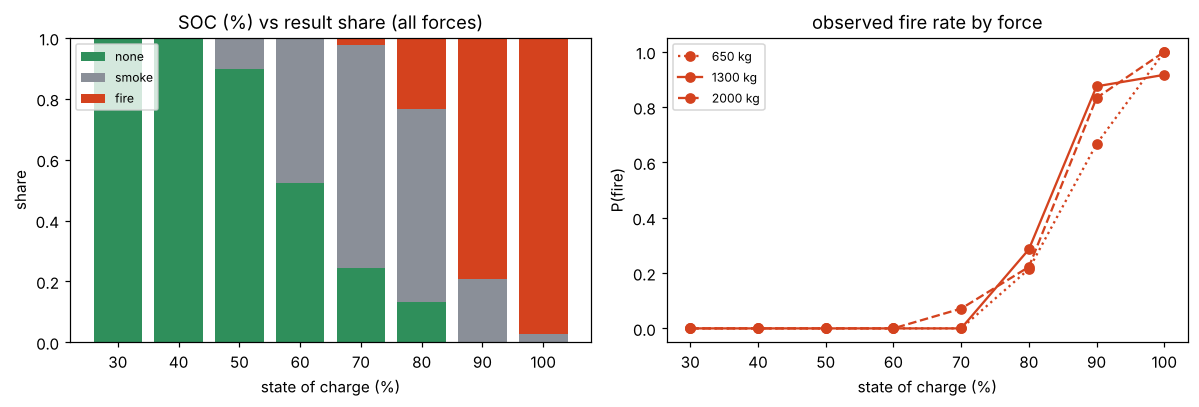

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bottom = np.zeros(len(rate))
for lab in LABELS:
    axes[0].bar(rate.index.astype(str), rate[lab], bottom=bottom, color=COL[lab], label=lab)
    bottom += rate[lab].values
axes[0].set_title("SOC (%) vs result share (all forces)")
axes[0].set_xlabel("state of charge (%)"); axes[0].set_ylabel("share"); axes[0].legend(loc="upper left", fontsize=8)

for F, ls in zip([650, 1300, 2000], [":", "-", "--"]):
    sub = df[df.force_kg == F]
    r = sub.groupby("soc_pct").result.apply(lambda s: (s == 2).mean())
    axes[1].plot(r.index, r.values, ls, marker="o", label=f"{F} kg", color="#d4421e")
axes[1].set_title("observed fire rate by force"); axes[1].set_xlabel("state of charge (%)"); axes[1].set_ylabel("P(fire)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. 뉴스 사례 4점의 함정 — 완전 분리

뉴스의 점 4개(30·50·70·100%, 1,300 kg)는 "화염"이 100%에서만 나서 **충전율 하나로 결과가 완벽히 갈립니다.**
이럴 때 규제 없이 로지스틱을 맞추면, 학습을 오래 할수록 기울기가 계속 커집니다(최대우도 추정이 존재하지 않음 — Albert & Anderson 1984).

In [5]:
xn = ((news.soc_pct - 70) / 10).to_numpy().reshape(-1, 1)
yn = (news.result == 2).astype(int).to_numpy()
print("뉴스 4점:", list(zip(news.soc_pct, news.result_label)))

rows = []
for C in [1, 10, 100, 1e3, 1e4, 1e6]:            # C가 클수록 규제가 약하다 (C = 1/λ)
    m = LogisticRegression(C=C, max_iter=100000, tol=1e-10).fit(xn, yn)
    rows.append(dict(C=C, 기울기_b=round(m.coef_[0][0], 2), 오즈배수_e_b=f"{np.exp(m.coef_[0][0]):.3g}",
                     P_fire_80pct=round(m.predict_proba([[1.0]])[0, 1], 3)))
pd.DataFrame(rows)

뉴스 4점: [(100, 'fire'), (70, 'smoke'), (50, 'none'), (30, 'none')]


,C,기울기_b,오즈배수_e_b,P_fire_80pct
0,1.0,0.85,2.34,0.361
1,10.0,1.84,6.3,0.282
2,100.0,3.05,21.2,0.178
3,1000.0,4.36,77.9,0.102
4,10000.0,5.71,302,0.054
5,1000000.0,8.51,4.99e+03,0.014


In [6]:
import statsmodels.api as sm
try:
    with warnings.catch_warnings():
        warnings.simplefilter("error")
        res = sm.Logit(yn, sm.add_constant(xn)).fit(disp=False, maxiter=200)
    print("기울기:", res.params)
except Exception as err:
    print("statsmodels도 맞추지 못합니다 →", type(err).__name__, ":", str(err)[:120])

statsmodels도 맞추지 못합니다 → PerfectSeparationWarning : Perfect separation or prediction detected, parameter may not be identified


**읽는 법**: 규제가 약해질수록(C↑) 기울기 b와 오즈 배수가 끝없이 커지고, 80% 화염 확률은 0이나 1 근처로 붙습니다.
점 4개는 "70%와 100% 사이 어딘가에 경계가 있다"는 것만 말해 줄 뿐, **80%에서 몇 %인지는 말하지 못합니다.**
해법: ① 규제(L2) ② Firth 보정 ③ **경계 근처(70~90%)에서 반복 실험** — 가장 근본적인 해법은 ③입니다.

## 4. 순서형 로지스틱 (비례 오즈) — 페이지와 같은 식

결과가 "변화 없음 < 연기 < 화염"으로 순서가 있으므로, 두 곡선이 **기울기를 함께 쓰고 출발점만 다른** 비례 오즈 모형(McCullagh 1980)을 씁니다.
statsmodels의 `OrderedModel`은 $P(y\le j)=\sigma(\theta_j - x\beta)$ 꼴이므로, 페이지의 $a_{연기}=-\theta_1$, $a_{화염}=-\theta_2$ 입니다.

In [7]:
def features(d):
    return pd.DataFrame({
        "x_soc": (d.soc_pct - 70) / 10,          # b
        "x_F": np.log(d.force_kg / 1300),        # c
        "shape": d.shape_code.astype(float),     # d  (+1 원통형, −1 각형, 0 둘 다)
        "x_T": (d.ambient_c - 25) / 10,          # e
    })

X = features(df)
y = pd.Series(pd.Categorical(df.result_label, categories=LABELS, ordered=True))
om = OrderedModel(y, X, distr="logit").fit(method="bfgs", disp=False, maxiter=2000)
print(om.summary())

                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -119.86
Model:                   OrderedModel   AIC:                             251.7
Method:            Maximum Likelihood   BIC:                             273.9
Date:                Tue, 17 Nov 2026                                         
Time:                        08:46:55                                         
No. Observations:                 300                                         
Df Residuals:                     294                                         
Df Model:                           4                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x_soc          1.9268      0.177     10.877      0.000       1.580       2.274
x_F            0.7142      0.375      1.907      0.0

In [8]:
th = om.model.transform_threshold_params(om.params)       # [-inf, θ1, θ2, inf]
est = dict(a_smoke=-th[1], a_fire=-th[2], b=om.params["x_soc"], c=om.params["x_F"], d=om.params["shape"], e=om.params["x_T"])
cmp = pd.DataFrame({"가정 모형(페이지)": TRUE, "300회로 추정": {k: round(v, 3) for k, v in est.items()}})
cmp["뜻"] = ["연기 이상 출발점", "화염 출발점", "충전율 10%p당 로그 오즈", "ln(압력/1300)당", "원통형(+1)·각형(−1)", "온도 10 °C당"]
print(f"충전율 10%p 오를 때 오즈 배수 e^b = {np.exp(est['b']):.2f}배 (가정 모형 {np.exp(TRUE['b']):.2f}배)")
cmp

충전율 10%p 오를 때 오즈 배수 e^b = 6.87배 (가정 모형 7.69배)


,가정 모형(페이지),300회로 추정,뜻
a_smoke,1.735,1.376,연기 이상 출발점
a_fire,-3.178,-2.881,화염 출발점
b,2.040,1.927,충전율 10%p당 로그 오즈
c,1.500,0.714,ln(압력/1300)당
d,0.300,0.226,원통형(+1)·각형(−1)
e,0.500,0.267,온도 10 °C당


### 확률 곡선 그리기 (1,300 kg · 형태 평균 · 25 °C)

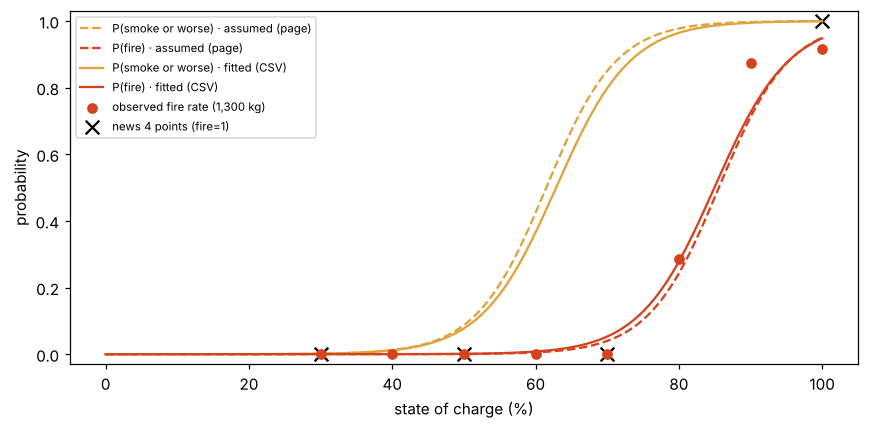

In [9]:
def probs(p, soc, F=1300, shape=0.0, T=25):
    eta = p["b"] * (soc - 70) / 10 + p["c"] * np.log(F / 1300) + p["d"] * shape + p["e"] * (T - 25) / 10
    sig = lambda z: 1 / (1 + np.exp(-z))
    ps, pf = sig(p["a_smoke"] + eta), sig(p["a_fire"] + eta)
    return ps, pf          # P(연기 이상), P(화염)

s = np.linspace(0, 100, 201)
fig, ax = plt.subplots(figsize=(8, 4))
for p, ls, nm in [(TRUE, "--", "assumed (page)"), (est, "-", "fitted (CSV)")]:
    ps, pf = probs(p, s)
    ax.plot(s, ps, ls, color="#e0a23a", label=f"P(smoke or worse) · {nm}")
    ax.plot(s, pf, ls, color="#d4421e", label=f"P(fire) · {nm}")
sub = df[df.force_kg == 1300]
obs = sub.groupby("soc_pct").result.agg(lambda r: (r == 2).mean())
ax.scatter(obs.index, obs.values, color="#d4421e", zorder=5, label="observed fire rate (1,300 kg)")
ax.scatter(news.soc_pct, (news.result == 2).astype(int), marker="x", s=80, color="k", label="news 4 points (fire=1)")
ax.set_xlabel("state of charge (%)"); ax.set_ylabel("probability"); ax.legend(fontsize=7.5); ax.set_ylim(-0.03, 1.03)
plt.tight_layout(); plt.show()

## 5. 화염/비화염 L2 로지스틱과 대결

실무에서 가장 궁금한 것은 "불이 나느냐"입니다. 화염(1)/비화염(0)으로 줄여 **L2 규제 로지스틱**을 맞추고, 5겹 교차검증 **로그 손실**(작을수록 확률을 정직하게 맞힘)로 규제 세기를 고릅니다.

In [10]:
yf = (df.result == 2).astype(int)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
res = []
for C in [0.01, 0.1, 1, 10, 100]:
    sc = cross_val_score(LogisticRegression(C=C, max_iter=5000), X, yf, cv=cv, scoring="neg_log_loss")
    res.append(dict(C=C, 교차검증_로그손실=round(-sc.mean(), 4), 편차=round(sc.std(), 4)))
res = pd.DataFrame(res)
bestC = res.loc[res.교차검증_로그손실.idxmin(), "C"]
print("가장 좋은 C:", bestC)
res

가장 좋은 C: 1.0


,C,교차검증_로그손실,편차
0,0.01,0.2641,0.0189
1,0.10,0.1613,0.0339
2,1.00,0.1456,0.0528
3,10.00,0.1523,0.0668
4,100.00,0.1541,0.0699


In [11]:
# 대결: 주판봇(뉴스 4점, 규제 거의 없음) vs 초파리(실험 데이터 절반 + L2) — 판정은 남은 절반(본 적 없는 실험)의 로그 손실
idx = np.random.default_rng(1).permutation(len(df))
tr, te = df.iloc[idx[:150]], df.iloc[idx[150:]]
robo = LogisticRegression(C=1e6, max_iter=100000).fit(features(news), (news.result == 2).astype(int))
fly = LogisticRegression(C=bestC, max_iter=5000).fit(features(tr), (tr.result == 2).astype(int))
yte = (te.result == 2).astype(int)
p_r = np.clip(robo.predict_proba(features(te))[:, 1], 1e-6, 1 - 1e-6)
p_f = fly.predict_proba(features(te))[:, 1]
print(f"주판봇(뉴스 4점) 로그 손실 {log_loss(yte, p_r):.3f} · 정확도 {((p_r > .5) == yte).mean():.2f}")
print(f"초파리(실험 150회 + L2) 로그 손실 {log_loss(yte, p_f):.3f} · 정확도 {((p_f > .5) == yte).mean():.2f}")

주판봇(뉴스 4점) 로그 손실 0.192 · 정확도 0.95
초파리(실험 150회 + L2) 로그 손실 0.168 · 정확도 0.95


두 손실을 견주어 보세요(랜덤 분할이라 숫자는 조금씩 다릅니다). 주판봇 모델은 확률을 0%나 100% 가까이에 붙이므로,
맞힌 비율이 비슷해도 **틀리는 셀에서 손실이 크게 튑니다.** 아래 셀은 주판봇이 가장 "자신 있게" 틀린 실험 5개입니다.

In [12]:
te2 = te.assign(p_robo=p_r.round(4), p_fly=p_f.round(3),
                loss_robo=-(yte * np.log(p_r) + (1 - yte) * np.log(1 - p_r)).round(2))
te2.sort_values("loss_robo", ascending=False)[["soc_pct", "force_kg", "ambient_c", "result_label", "p_robo", "p_fly", "loss_robo"]].head(5)

,soc_pct,force_kg,ambient_c,result_label,p_robo,p_fly,loss_robo
100,100,1300,25,smoke,0.9999,0.930,9.02
236,90,1300,25,smoke,0.9701,0.667,3.51
252,90,2000,40,smoke,0.9701,0.843,3.51
240,80,2000,25,fire,0.1130,0.268,2.18
125,80,1300,25,fire,0.1130,0.224,2.18


## 6. 충전율 기준 표 — 30 · 50 · 80 · 100%

하루 택배 10만 개 중 강한 충격을 받는 비율(예시값)을 곱해 "하루 예상 화염 건수"를 봅니다. 택배 충격은 1,300 kg 압착과 같지 않습니다 — 비교를 위한 예시입니다.

In [13]:
HIT = 0.001          # 강한 충격 비율 (예시값 0.1%)
PARCELS = 100_000
rows = []
for soc in [30, 50, 80, 100]:
    _, pf_true = probs(TRUE, soc)
    _, pf_est = probs(est, soc)
    rows.append({"충전율 %": soc, "P(화염) 가정": round(pf_true, 4), "P(화염) 추정": round(pf_est, 4),
                 "하루 예상 화염 건수(추정)": round(PARCELS * HIT * pf_est, 2)})
pd.DataFrame(rows)

,충전율 %,P(화염) 가정,P(화염) 추정,하루 예상 화염 건수(추정)
0,30,0.0000,0.0000,0.00
1,50,0.0007,0.0012,0.12
2,80,0.2427,0.2781,27.81
3,100,0.9499,0.9478,94.78


## 해 보기
1. 페이지에서 **80~90%만 골라 20번씩** 압착하고 "내 실험 기록 CSV"를 받아 4번 셀을 다시 돌려 보세요. 계수 b의 표준오차가 어떻게 바뀌나요?
2. 2,000 kg 실험만 남기고(`df[df.force_kg==2000]`) 순서형 로지스틱을 맞추면 `x_F` 계수는 어떻게 되나요? (힌트: 변하지 않는 입력은 추정할 수 없다)
3. `HIT`를 0.01%~1%로 바꿔 보며, 보관·유통 충전율 기준을 30%로 두는 것과 50%로 두는 것의 차이를 숫자로 말해 보세요.

**참고문헌**: McCullagh (1980) 순서형 회귀 · Albert & Anderson (1984) 완전 분리 · Firth (1993) 편향 보정 · Feng 외 (2018) 열폭주 메커니즘.
캐릭터 이름·설정·그림은 저작권자 안상선의 허락 없이 사용할 수 없습니다.